In [1]:
%matplotlib inline

import itertools
import json
import math
import random
import string
from collections.abc import Iterable

import geopandas as gpd
import matplotlib.pyplot as plt
import shapely.geometry as geom

from weavingspace import TileUnit, Tiling

num = int | float

In [2]:
"""Manually transcoded from javascript implementation of

JE Soto Sánchez, T Weyrich, LH de Figueiredo, A Medeiros e Sá. 2021. An integer
representation for periodic tilings of the plane with regular polygons Computer
& Graphics 95 69-80. doi: 10.1016/j.cag.2021.01.007

available at https://chequesoto.info/tiling/
"""

# sequence a, b,... z, aa, ab,... az, ba, and so on, for labelling tiles
TILE_IDS = [
  *string.ascii_lowercase,
  *["".join(x) for x in itertools.product(
    string.ascii_lowercase, string.ascii_lowercase)]
]

EPS = 1e-4
SQRT3 = math.sqrt(3) / 2

# unit vectors in four 30º directions in the first quadrant
X_BASE = 1, SQRT3, 0.5, 0
Y_BASE = 0, 0.5, SQRT3, 1

# Coordinates of the twelve 30º spaced unit vectors expressed as combinations
# of the 0, 30, 60, and 90º unit vectors (described in the Soto Sanchéz paper as
# the 12th root of unity in the complex plane). The first four are the basis,
# all others are linear combinations of these four.
BASE_COORDS = (
  ( 1,  0,  0,  0),  # ω^0, i.e., to right along x-axis
  ( 0,  1,  0,  0),  # ω^1, up to right at 30º
  ( 0,  0,  1,  0),  # ω^2, up to right at 60º
  ( 0,  0,  0,  1),  # ω^3, ... and so on
  (-1,  0,  1,  0),  # e.g, this one is left, then up to right at 60º, ω^0 + ω^2
  ( 0, -1,  0,  1),
  (-1,  0,  0,  0),
  ( 0, -1,  0,  0),
  ( 0,  0, -1,  0),
  ( 0,  0,  0, -1),
  ( 1,  0, -1,  0),
  ( 0,  1,  0, -1),
)

# 15 species of vertex that may appear in regular tilings including
# cyclic matches, such as 3.3.4.12 and 4.3.3.12
VERTEX_TYPE = {
  (3, 12, 12): 0,
  (4, 6, 12): 1,
  (6, 4, 12): 1,
  (4, 4, 8): 2,
  (6, 6, 6): 3,
  (3, 3, 4, 12): 4,
  (4, 3, 3, 12): 4,
  (3, 4, 3, 12): 5,
  (4, 4, 3, 6): 6,
  (3, 4, 4, 6): 6,
  (4, 3, 4, 6): 7,
  (3, 3, 6, 6): 8,
  (3, 6, 3, 6): 9,
  (4, 4, 4, 4): 10,
  (3, 3, 3, 4, 4): 11,
  (3, 3, 4, 3, 4): 12,
  (3, 3, 3, 3, 6): 13,
  (3, 3, 3, 3, 3, 3): 14,
}


In [3]:
# read tile specs from supplied JSON
# note that there are definitely duplicates
with open("tiles.json") as file:
  Symbols1 = json.load(file)
with open("tiles-2.json") as file:
  Symbols2 = json.load(file)
Symbols = Symbols1 | Symbols2

In [20]:
def change_base(a:Iterable[num],
                t1:Iterable[num],
                t2:Iterable[num]) -> Iterable[num]:
  """Transform supplied vector to specified basis.

  Args:
    a (Iterable[num]): vector to transform.
    t1 (Iterable[num]): first basis vector.
    t2 (Iterable[num]): second basis vector.

  Returns:
    Iterable[num]: transformed vector.

  """
  det = t1[0] * t2[1] - t1[1] * t2[0]
  d1 = a[0] * t2[1] - a[1] * t2[0]
  d2 = t1[0] * a[1] - t1[1] * a[0]
  return d1 / det, d2 / det


def circle_list(lst:list) -> list:
  """Return list cycled one position.

  Args:
    lst (list): list to cycle.

  Returns:
    list: supplied list shifted one position.

  """
  return [lst[-1], *lst[:-1]]


def class_vertex(symbol:list[int]) -> int:
  """Determine which vertex type the supplied list of ints matches.

  Args:
    symbol (list[int]): list of number of sides of polygons incident at vertex.

  Returns:
    int: species of supplied symbol per VERTEX_TYPE dictionary.

  """
  new_symbol = symbol
  count = 0
  if len(new_symbol) < 3: return -1
  while new_symbol not in VERTEX_TYPE and count < len(symbol):
    new_symbol = tuple(circle_list(new_symbol))
    count = count + 1
  return VERTEX_TYPE[new_symbol]


def base_to_point(coords:Iterable[int]) -> tuple[float]:
  """Convert supplied integer coordinates to point in Euclidean space.

  Args:
    coords (Iterable[int]): 4-tuple of integer coordinates.

  Returns:
    tuple[float]: corresponding tuple of coordinates in Euclidean space.

  """
  return sum(s * x for s, x in zip(coords, X_BASE, strict = True)), \
         sum(s * y for s, y in zip(coords, Y_BASE, strict = True))


def get_face_points(points:Iterable[Iterable[int]],
                    t1:Iterable[int],
                    t2:Iterable[int]) -> tuple[int]:
  """Get points in fundamental unit and neighbouring fundamental units.

  Applies translation vectors to augment list of supplied points with matching
  points in each translation vector direction, and also one move diagonally,
  i.e. at (0, 0), (0, 1), (1, 0), and (1, 1).

  Args:
    points (Iterable[int]): points in base tile.
    t1 (Iterable[int]): first translation vector.
    t2 (Iterable[int]): second translation vector.

  Returns:
    tuple[int]: extended tuple of points in base tile and matching points
      offset by translation vectors.

  """
  patch = []
  for k1 in range(2):
    for k2 in range(2):
      for point in points:
        t = tuple(k1 * u + k2 * v for u, v in zip(t1, t2, strict = True))
        patch.append(tuple(x + y for x, y in zip(point, t, strict = True)))
  return patch


def get_patch_hash(points:Iterable[Iterable[int]],
                   t1:Iterable[int],
                   t2:Iterable[int],
                   n0:int = -1, n1:int = 2) -> dict[tuple[int]:int]:
  """Get dictionary with integer tuple keys for all points in local patch.

  Args:
    points (Iterable[int]): points in base tile.
    t1 (Iterable[int]): first translation vector.
    t2 (Iterable[int]): second translation vector.
    n0 (int): lower bound on offset tiles to check in patch.
    n1 (int): upper bound on offset tiles to check in patch.

  Returns:
    dict[tuple[int]:int]: a dictionary keyed by base tile integer coordinates
      of all points and their matching points in the surrounding patch.

  """
  patch = {}
  # note both loops n0 to n1 _inclusive_
  for k1 in range(n0, n1 + 1):
    for k2 in range(n0, n1 + 1):
      for point in points:
        # all coords are ints so form a safe integer tuple dictionary key
        hashcode = tuple(p + k1 * u + k2 * v
                         for p, u, v in zip(point, t1, t2, strict = True))
        patch[hashcode] = 1
  return patch


def star_build(point, patch):
  star = []
  for k in range(12):
    candidate = tuple(
      round(x + dx, 6) for x, dx in zip(point, BASE_COORDS[k], strict = True))
    if candidate in patch:
      star.append(k)
  return star


def omega_to_poly(angle:int) -> int:
  """Return polygon degree based on angle supplied as multiple of 30º.

  Args:
    angle (int): number of 30º turns.

  Returns:
    int: number of sides of regular polygon.

  """
  k = abs(angle)
  n = 0
  return (3 if k == 2
    else  4 if k == 3
    else  6 if k == 4
    else 12 if k == 5
    else omega_to_poly(12 - k) if k >= 6
    else None)
  return n


def get_face(w, i, n):
  J = math.floor(12 / n)
  centre = [0, 0, 0, 0]
  p = w
  face = [w]
  for j in range(0, 12, J):
    p = [x + dx for x, dx in zip(p, BASE_COORDS[(i + j) % 12], strict = True)]
    centre = [c + x for c, x in zip(centre, p, strict = True)]
    face.append(p)
  # I think the times-6 factor keeps all the numbers integer?
  return tuple(int(6 * c / n) for c in centre), face[:-1]


def star_to_faces(star, centre):
  centroids, faces = [], []
  for left, right in zip(star, [*star[1:], star[0]], strict = True):
    n = omega_to_poly((right - left) % 12)
    if n > 0:
      result = get_face(centre, left, n)
      centroids.append(result[0])
      faces.append(result[1])
  return centroids, faces


def star_class(star, centre):
  symbol = []
  for left, right in zip(star, [*star[1:], star[0]], strict = True):
    n = omega_to_poly((right - left) % 12)
    symbol.append(n)
  return class_vertex(tuple(symbol))


def w_region_test(p, t1, t2):
  U = change_base(base_to_point(p), base_to_point(t1), base_to_point(t2))
  return ((U[0] >= -EPS) and (U[0] < 1 - EPS) and 
          (U[1] >= -EPS) and (U[1] < 1 - EPS))


def mesh_build(tile):
  mesh1 = ArchMesh()
  if tile not in ["t1002", "J"]:
    ts1 = Symbols[tile]["T1"]
    ts2 = Symbols[tile]["T2"]
    seed = Symbols[tile]["Seed"]
    face_points = get_face_points(seed, ts1, ts2)
    patch = get_patch_hash(seed, ts1, ts2)
    faces = []
    centroids = []
    centroids_hash = {}
    for face_point in face_points:
      these_centroids, these_faces = \
        star_to_faces(star_build(face_point, patch), face_point)
      for centroid, face in zip(these_centroids, these_faces, strict = True):
        # centroid is integer tuple so can be safely used as dictionary key
        if centroid not in centroids_hash and \
            w_region_test([c / 6 for c in centroid], ts1, ts2):
          centroids_hash[centroid] = 1
          faces.append(face)
          centroids.append(centroid)
    mesh1.tvec1 = ts1
    mesh1.tvec2 = ts2
    mesh1.vertex_set = seed
    mesh1.poly_sets = faces
    mesh1.dual_points = centroids
    mesh1.vertex_types = [star_class(star_build(s, patch), s) for s in seed]
  else:
    ct = math.sqrt(2) / 2
    mesh1.tvec1 = [1 + ct, 0, 0, 1 + ct]
    mesh1.tvec2 = [3.4142, 0, 0, 0]
    mesh1.vertex_set = [
      [0, 0, 0, 0], [1, 0, 0, 0], [1, 0, 0, 1], [0, 0, 0, 1]]
    mesh1.poly_sets = [
      [[0, 0, 0, 0], [1, 0, 0, 0], [1, 0, 0, 1], [0, 0, 0, 1]],
      [[1, 0, 0, 0], [1, 0, 0, 1], [1 + ct, 0, 0, 1 + ct], 
       [2 + ct, 0, 0, 1 + ct], [2 + 2 * ct, 0, 0, 1], [2 + 2 * ct, 0, 0, 0],
       [2 + ct, 0, 0, -ct], [1 + ct, 0, 0, -ct]]]
    mesh1.dual_points = [[3, 0, 0, 3], [9 + 6 * ct, 0, 0, 3]]
    mesh1.vertex_types = [2, 2, 2, 2]
  return mesh1


class ArchMesh:
  def __init__(self):
    self.tvec1 = tuple()
    self.tvec2 = tuple()
    self.vertex_set = []
    self.poly_sets = []
    self.dual_points = []
    self.origin = tuple()
    self.vertex_types = {}


In [21]:
rect = gpd.GeoDataFrame(
  geometry = gpd.GeoSeries(
    [geom.Polygon([(-1500, -900), (-1500, 900), (1500, 900), (1500, -900)])]),
  crs = 3857, data = {"x" : [1]}
)

In [22]:
def get_tile(code, scale = 50):
  mesh = mesh_build(code)
  n = len(mesh.poly_sets)
  polys = []
  for points in mesh.poly_sets:
    polys.append(geom.Polygon([base_to_point(xy) for xy in points]))
  t = TileUnit()
  t.tiles = gpd.GeoDataFrame(
    geometry = gpd.GeoSeries(polys), crs = 3857,
    data = {"tile_id": TILE_IDS[:len(polys)]} 
  )
  t.setup_vectors(base_to_point(mesh.tvec1), base_to_point(mesh.tvec2))
  t.prototile = t.get_prototile_from_vectors()
  t._setup_regularised_prototile(True)
  return t.transform_scale(scale, scale)  

In [25]:
code = "t7u001" # "t1009" # 
mesh = mesh_build(code)
edges = []
for k, points in enumerate(mesh.poly_sets):
  Q = base_to_point([x / 6 for x in mesh.dual_points[k]])
  for p1, p2 in zip(points, [*points[1:], points[0]]):
    P1 = base_to_point(p1)
    P2 = base_to_point(p2)
    R = [(x + y) / 2 for x, y in zip(P1, P2)]
    edges.append(geom.LineString([Q, R]))
dual_edges = gpd.GeoSeries(edges)

<Axes: >

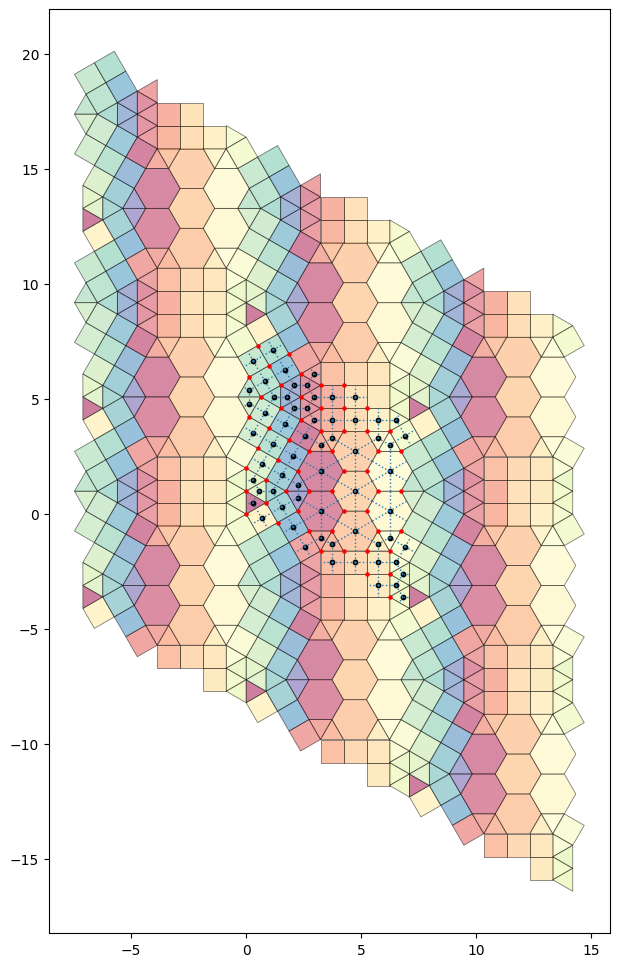

In [30]:
ax = get_tile(code, scale = 1).plot(
  r = 1, alpha = 0.5,
  show_ids = False, show_vectors = False,
  show_prototile = False, show_reg_prototile = False,
  ec = "k", lw = 0.6, figsize = (12, 12))
dual_edges.plot(ax = ax, lw = 1, ls = ":")
gpd.GeoSeries(geom.MultiPoint([base_to_point([x / 6 for x in c]) for c in mesh.dual_points])).plot(ax = ax, markersize = 10, color = "k")
gpd.GeoSeries(geom.MultiPoint([base_to_point(xy) for xy in mesh.vertex_set])).plot(ax = ax, color = "r", markersize = 5)

<Axes: >

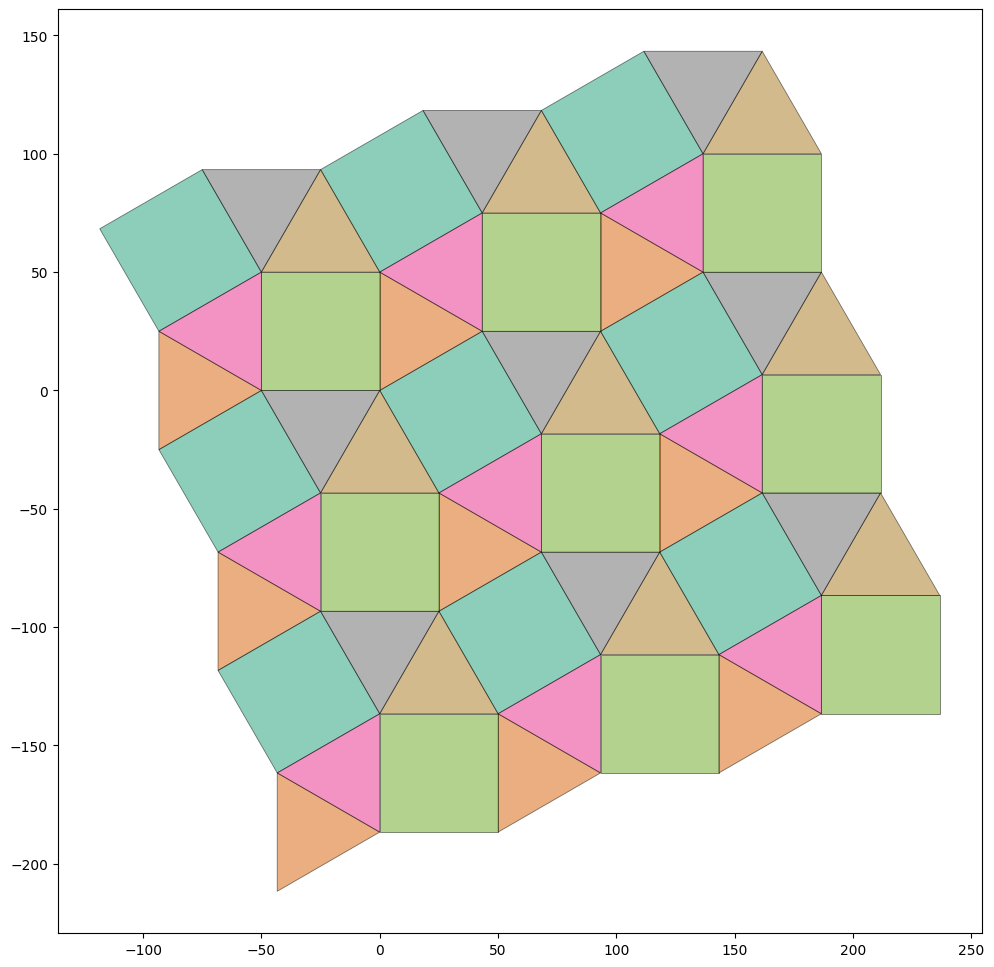

In [19]:
get_tile("t1009").plot(
  r = 1, alpha = 0.5,
  show_ids = False, show_vectors = False,
  show_prototile = False, show_reg_prototile = False,
  ec = "k", lw = 0.6, figsize = (12, 12))

In [10]:
def plot_tiling(code, region = rect):
  unit = get_tile(code)
  tiling = Tiling(unit, rect)
  fig = plt.figure(figsize = (10, 6), layout = "constrained")
  ax = fig.add_subplot(111)
  tiling.tiles.plot(ax = ax,
    column = "tile_id", ec = "w", lw = 0.5, cmap = "magma")
  ax.set_title(f"{code} (n={unit.tiles.shape[0]})")
  ax.set_axis_off()
  ax.set_xlim((-1200, 1200))
  ax.set_ylim((-720, 720))

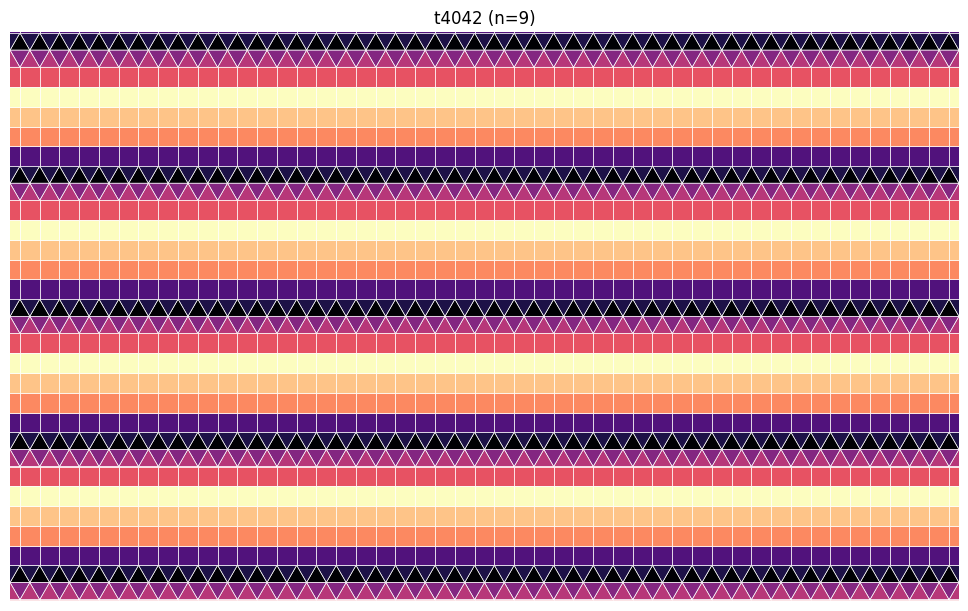

In [11]:
plot_tiling(random.choice(list(Symbols.keys())))